# Olist Brazilian E-Commerce — General EDA
Overview of all 9 tables: structure, missing values, duplicates, key relationships, and the main business patterns (orders, payments, delivery, reviews, geography).

In [1]:
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")
dfs = {
    f.removeprefix("olist_").removesuffix("_dataset.csv").removesuffix(".csv"): pd.read_csv(os.path.join(path, f))
    for f in os.listdir(path) if f.endswith(".csv")
}
customers, geolocation, orders = dfs["customers"], dfs["geolocation"], dfs["orders"]
items, payments, reviews = dfs["order_items"], dfs["order_payments"], dfs["order_reviews"]
products, sellers, translation = dfs["products"], dfs["sellers"], dfs["product_category_name_translation"]

c:\Users\ferna\br_e-commerce\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Table overview

In [2]:
summary = pd.DataFrame({
    name: {
        "rows": df.shape[0],
        "cols": df.shape[1],
        "cols_with_nulls": int(df.isna().any().sum()),
        "null_cells_%": df.isna().sum().sum() / df.size * 100,
        "duplicate_rows": int(df.duplicated().sum()),
        "memory_MB": df.memory_usage(deep=True).sum() / 1e6,
    }
    for name, df in dfs.items()
}).T
summary

,rows,cols,cols_with_nulls,null_cells_%,duplicate_rows,memory_MB
customers,"99,441.00",5.00,0.00,0.00,0.00,27.88
geolocation,"1,000,163.00",5.00,0.00,0.00,"261,831.00",136.59
orders,"99,441.00",8.00,3.00,0.62,0.00,55.51
order_items,"112,650.00",7.00,0.00,0.00,0.00,37.74
order_payments,"103,886.00",5.00,0.00,0.00,0.00,17.02
order_reviews,"99,224.00",7.00,2.00,21.01,0.00,41.03
products,"32,951.00",9.00,8.00,0.83,0.00,6.60
sellers,"3,095.00",4.00,0.00,0.00,0.00,0.62
product_category_name_translation,71.00,2.00,0.00,0.00,0.00,0.01


## 2. Schema and dtypes per table

In [3]:
for name, df in dfs.items():
    print(f"=== {name} {df.shape} ===")
    print(pd.DataFrame({"dtype": df.dtypes.astype(str), "nulls": df.isna().sum(),
                        "null_%": df.isna().mean() * 100, "unique": df.nunique()}))
    print()

=== customers (99441, 5) ===
                          dtype  nulls  null_%  unique
customer_id                 str      0    0.00   99441
customer_unique_id          str      0    0.00   96096
customer_zip_code_prefix  int64      0    0.00   14994
customer_city               str      0    0.00    4119
customer_state              str      0    0.00      27

=== geolocation (1000163, 5) ===
                               dtype  nulls  null_%  unique
geolocation_zip_code_prefix    int64      0    0.00   19015
geolocation_lat              float64      0    0.00  717360
geolocation_lng              float64      0    0.00  717613
geolocation_city                 str      0    0.00    8011
geolocation_state                str      0    0.00      27

=== orders (99441, 8) ===
                              dtype  nulls  null_%  unique
order_id                        str      0    0.00   99441
customer_id                     str      0    0.00   99441
order_status                    str      0 

## 3. Missing values

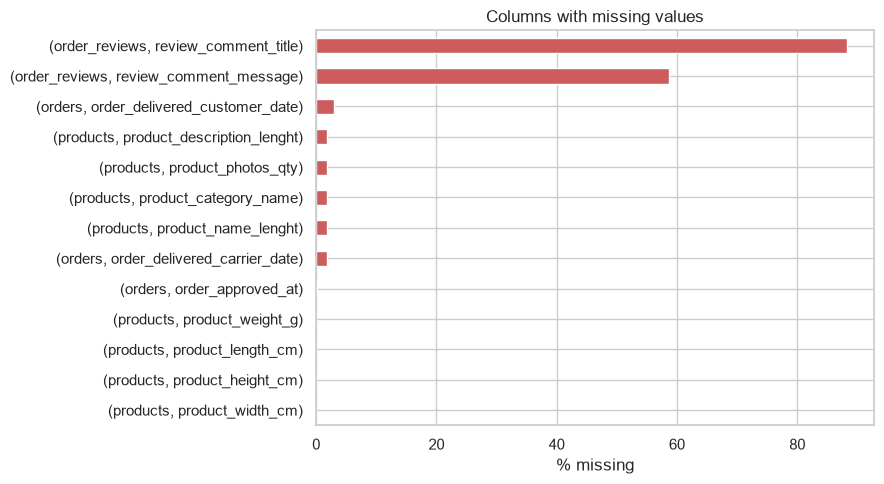

In [4]:
miss = pd.concat({n: d.isna().mean() * 100 for n, d in dfs.items()}).rename("null_%")
miss = miss[miss > 0].sort_values()
ax = miss.plot.barh(figsize=(9, 5), color="indianred")
ax.set_xlabel("% missing"); ax.set_title("Columns with missing values")
plt.tight_layout(); plt.show()

Notes:
- `orders`: missing delivery/approval dates correspond to orders not yet delivered (canceled, unavailable, shipped, ...). Checked below.
- `products`: ~610 products lack category/name/description/photos metadata.
- `order_reviews`: comment title/message are optional free text.

In [5]:
orders.groupby("order_status")[["order_approved_at", "order_delivered_carrier_date", "order_delivered_customer_date"]].agg(lambda s: s.isna().sum()).join(
    orders["order_status"].value_counts().rename("n_orders"))

,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,n_orders
order_status,,,,
approved,0,2,2,2
canceled,141,550,619,625
created,5,5,5,5
delivered,14,2,8,96478
invoiced,0,314,314,314
processing,0,301,301,301
shipped,0,0,1107,1107
unavailable,0,609,609,609


## 4. Duplicates and key integrity

In [6]:
def is_unique(df, cols): return not df.duplicated(cols).any()
keys = {
    "customers.customer_id": is_unique(customers, ["customer_id"]),
    "orders.order_id": is_unique(orders, ["order_id"]),
    "order_items (order_id, order_item_id)": is_unique(items, ["order_id", "order_item_id"]),
    "order_payments (order_id, payment_sequential)": is_unique(payments, ["order_id", "payment_sequential"]),
    "order_reviews.review_id": is_unique(reviews, ["review_id"]),
    "products.product_id": is_unique(products, ["product_id"]),
    "sellers.seller_id": is_unique(sellers, ["seller_id"]),
}
print(pd.Series(keys, name="is_unique_key").to_string())
print("\nGeolocation duplicate rows:", geolocation.duplicated().sum(), f"({geolocation.duplicated().mean():.0%})")
print("customer_unique_id vs customer_id:", customers.customer_unique_id.nunique(), "unique people for", customers.customer_id.nunique(), "customer_ids")
print("Reviews: orders with >1 review:", (reviews.order_id.value_counts() > 1).sum(), "| review_ids repeated:", reviews.review_id.duplicated().sum())

customers.customer_id                             True
orders.order_id                                   True
order_items (order_id, order_item_id)             True
order_payments (order_id, payment_sequential)     True
order_reviews.review_id                          False
products.product_id                               True
sellers.seller_id                                 True

Geolocation duplicate rows: 261831 (26%)
customer_unique_id vs customer_id: 96096 unique people for 99441 customer_ids
Reviews: orders with >1 review: 547 | review_ids repeated: 814


In [7]:
# Foreign-key coverage: share of child keys present in the parent table
def fk(child, col, parent, pcol=None):
    pcol = pcol or col
    return child[col].isin(parent[pcol]).mean() * 100
pd.Series({
    "orders.customer_id -> customers": fk(orders, "customer_id", customers),
    "order_items.order_id -> orders": fk(items, "order_id", orders),
    "order_items.product_id -> products": fk(items, "product_id", products),
    "order_items.seller_id -> sellers": fk(items, "seller_id", sellers),
    "order_payments.order_id -> orders": fk(payments, "order_id", orders),
    "order_reviews.order_id -> orders": fk(reviews, "order_id", orders),
    "products.category -> translation": fk(products.dropna(subset=["product_category_name"]), "product_category_name", translation),
    "customers.zip -> geolocation": fk(customers, "customer_zip_code_prefix", geolocation, "geolocation_zip_code_prefix"),
    "sellers.zip -> geolocation": fk(sellers, "seller_zip_code_prefix", geolocation, "geolocation_zip_code_prefix"),
}, name="% matched").to_frame()

,% matched
orders.customer_id -> customers,100.00
order_items.order_id -> orders,100.00
order_items.product_id -> products,100.00
order_items.seller_id -> sellers,100.00
order_payments.order_id -> orders,100.00
order_reviews.order_id -> orders,100.00
products.category -> translation,99.96
customers.zip -> geolocation,99.72
sellers.zip -> geolocation,99.77


In [8]:
print("Orders without items:", (~orders.order_id.isin(items.order_id)).sum())
print("Orders without payments:", (~orders.order_id.isin(payments.order_id)).sum())
print("Orders without reviews:", (~orders.order_id.isin(reviews.order_id)).sum())
orders[~orders.order_id.isin(items.order_id)].order_status.value_counts()

Orders without items: 775
Orders without payments: 1
Orders without reviews: 768


order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64

## 5. Orders

2016-09-04 21:15:19 -> 2018-10-17 17:30:18


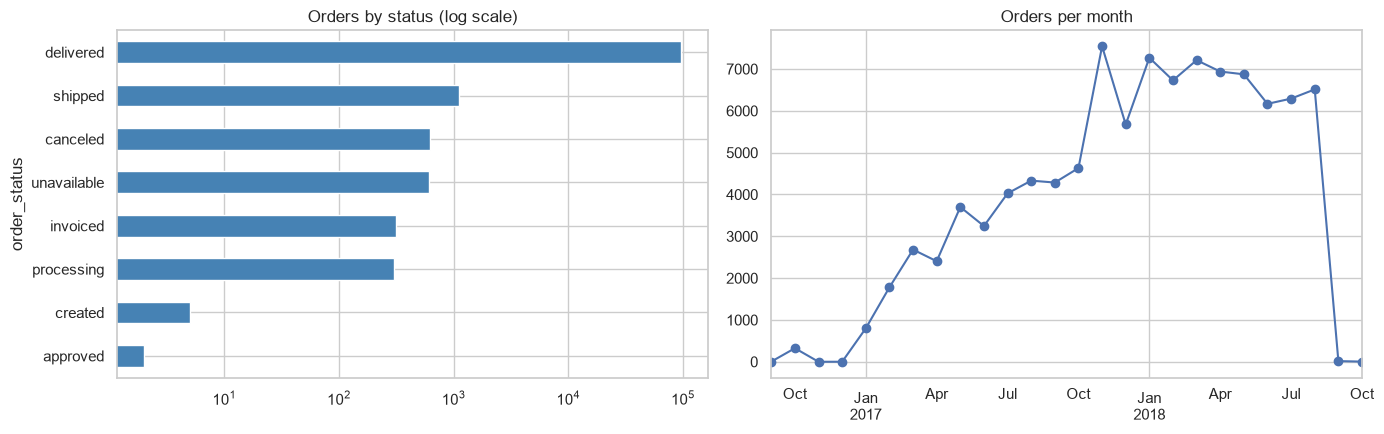

In [9]:
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
orders[date_cols] = orders[date_cols].apply(pd.to_datetime)
print(orders.order_purchase_timestamp.min(), "->", orders.order_purchase_timestamp.max())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
orders.order_status.value_counts().plot.barh(ax=axes[0], color="steelblue", logx=True)
axes[0].set_title("Orders by status (log scale)"); axes[0].invert_yaxis()
monthly = orders.set_index("order_purchase_timestamp").resample("MS").size()
monthly.plot(ax=axes[1], marker="o"); axes[1].set_title("Orders per month"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()

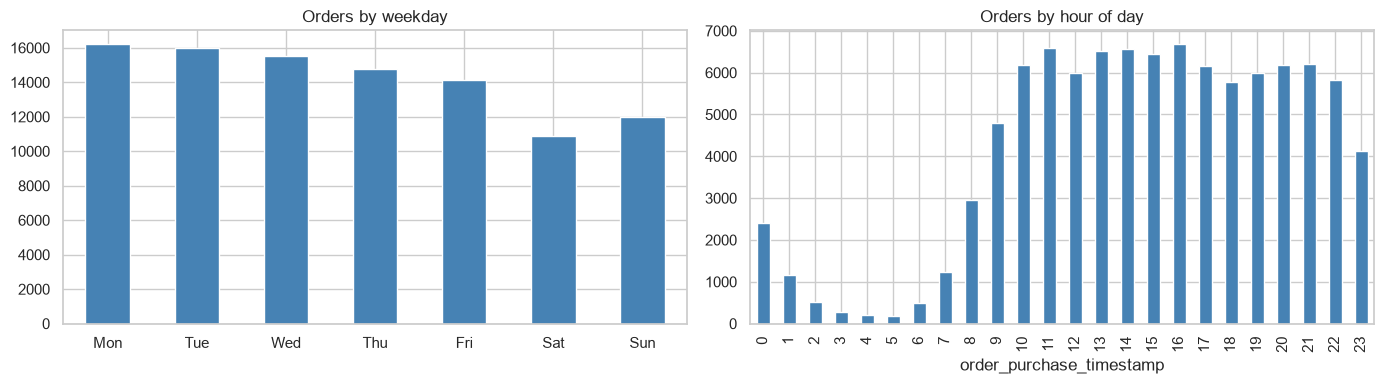

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
orders.order_purchase_timestamp.dt.dayofweek.value_counts().sort_index().set_axis(
    ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]).plot.bar(ax=axes[0], color="steelblue", rot=0)
axes[0].set_title("Orders by weekday")
orders.order_purchase_timestamp.dt.hour.value_counts().sort_index().plot.bar(ax=axes[1], color="steelblue")
axes[1].set_title("Orders by hour of day")
plt.tight_layout(); plt.show()

### Delivery performance

                   count  mean  std  min   25%   50%   75%    max
delivery_days  96,476.00 12.09 9.55 0.00  6.00 10.00 15.00 209.00
estimated_days 96,476.00 23.37 8.76 2.00 18.00 23.00 28.00 155.00

Late deliveries: 8.1%


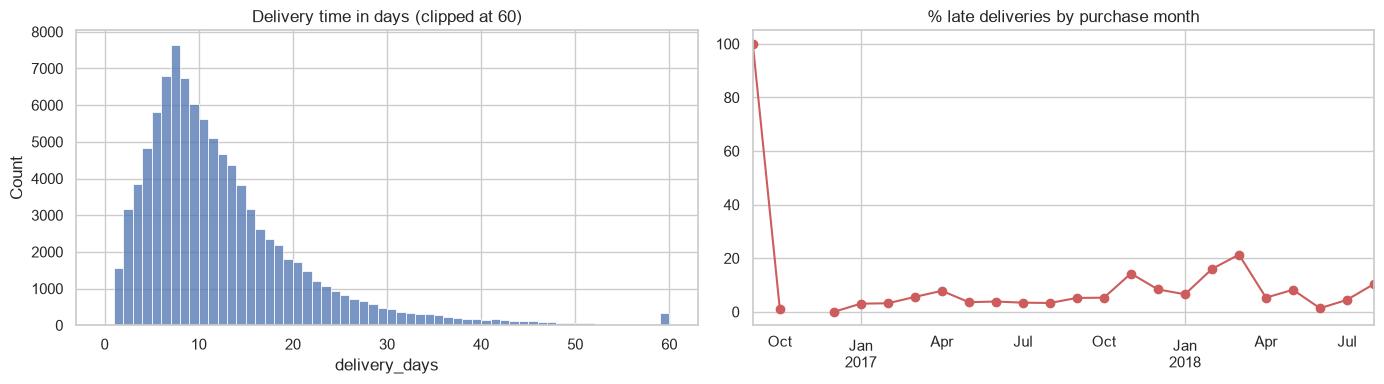

In [11]:
d = orders.dropna(subset=["order_delivered_customer_date"]).copy()
d["delivery_days"] = (d.order_delivered_customer_date - d.order_purchase_timestamp).dt.days
d["estimated_days"] = (d.order_estimated_delivery_date - d.order_purchase_timestamp).dt.days
d["late"] = d.order_delivered_customer_date > d.order_estimated_delivery_date
print(d[["delivery_days", "estimated_days"]].describe().T)
print(f"\nLate deliveries: {d.late.mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(d.delivery_days.clip(upper=60), bins=60, ax=axes[0]); axes[0].set_title("Delivery time in days (clipped at 60)")
late_m = d.set_index("order_purchase_timestamp").late.resample("MS").mean() * 100
late_m.plot(ax=axes[1], marker="o", color="indianred"); axes[1].set_title("% late deliveries by purchase month"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()

## 6. Order items, prices and freight

                   count   mean    std  min   25%   50%    75%      max
price         112,650.00 120.65 183.63 0.85 39.90 74.99 134.90 6,735.00
freight_value 112,650.00  19.99  15.81 0.00 13.08 16.26  21.15   409.68

Items per order:
1    88863
2     7516
3     1322
4      505
5      204
6      198
7       22
8        8


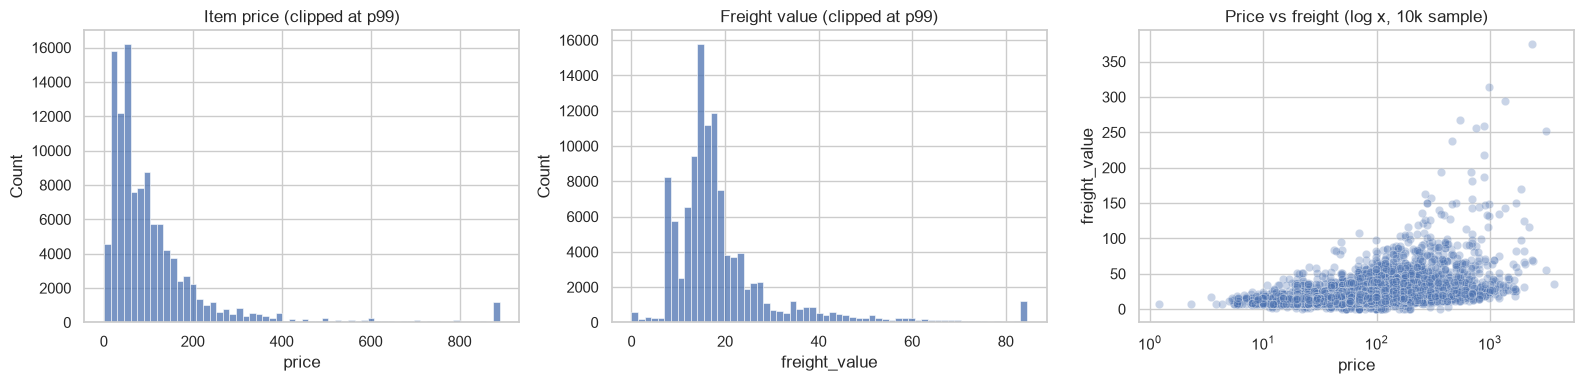

In [12]:
print(items[["price", "freight_value"]].describe().T)
print("\nItems per order:"); print(items.groupby("order_id").size().value_counts().sort_index().head(8).to_string())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(items.price.clip(upper=items.price.quantile(.99)), bins=60, ax=axes[0]); axes[0].set_title("Item price (clipped at p99)")
sns.histplot(items.freight_value.clip(upper=items.freight_value.quantile(.99)), bins=60, ax=axes[1]); axes[1].set_title("Freight value (clipped at p99)")
sns.scatterplot(data=items.sample(10000, random_state=0), x="price", y="freight_value", alpha=.3, ax=axes[2])
axes[2].set_xscale("log"); axes[2].set_title("Price vs freight (log x, 10k sample)")
plt.tight_layout(); plt.show()

## 7. Payments

payment_type
credit_card   73.90
boleto        19.00
voucher        5.60
debit_card     1.50
not_defined    0.00

Zero-value payments: 9 | 'not_defined' type: 3
Orders with >1 payment row: 2961


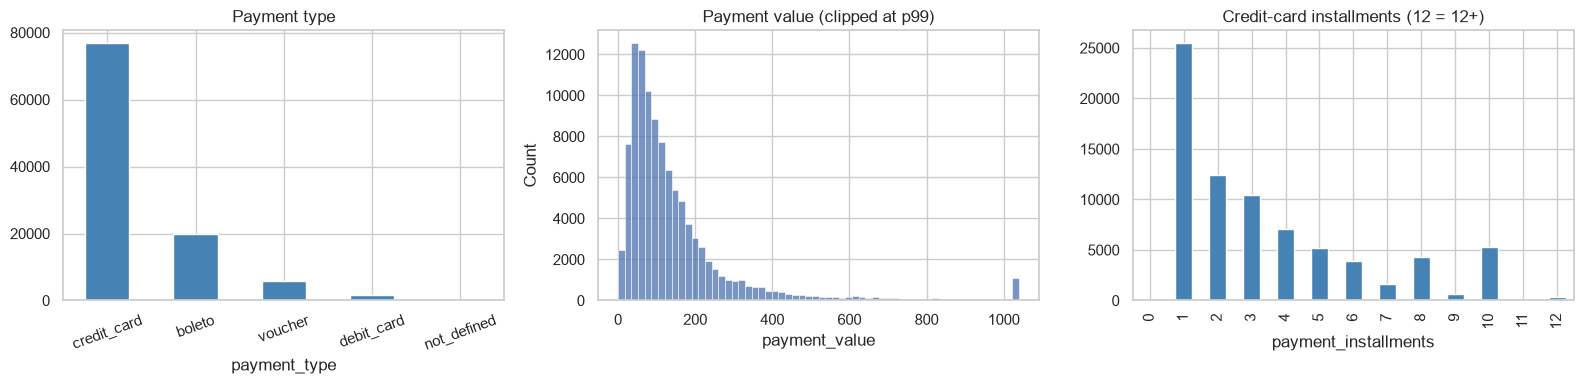

In [13]:
print(payments.payment_type.value_counts(normalize=True).mul(100).round(1).to_string())
print("\nZero-value payments:", (payments.payment_value == 0).sum(), "| 'not_defined' type:", (payments.payment_type == "not_defined").sum())
print("Orders with >1 payment row:", (payments.groupby("order_id").size() > 1).sum())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
payments.payment_type.value_counts().plot.bar(ax=axes[0], rot=20, color="steelblue"); axes[0].set_title("Payment type")
sns.histplot(payments.payment_value.clip(upper=payments.payment_value.quantile(.99)), bins=60, ax=axes[1]); axes[1].set_title("Payment value (clipped at p99)")
payments[payments.payment_type == "credit_card"].payment_installments.clip(upper=12).value_counts().sort_index().plot.bar(ax=axes[2], color="steelblue")
axes[2].set_title("Credit-card installments (12 = 12+)")
plt.tight_layout(); plt.show()

In [14]:
# Payments total should match items price + freight per order
chk = items.groupby("order_id")[["price", "freight_value"]].sum().sum(axis=1).rename("items_total").to_frame().join(
    payments.groupby("order_id").payment_value.sum().rename("paid"), how="inner")
chk["diff"] = chk.paid - chk.items_total
print(f"Orders where |paid - items_total| > 1 BRL: {(chk['diff'].abs() > 1).mean():.2%}")
chk["diff"].describe()

Orders where |paid - items_total| > 1 BRL: 0.25%


count   98,665.00
mean         0.03
std          1.13
min        -51.62
25%          0.00
50%          0.00
75%          0.00
max        182.81
Name: diff, dtype: float64

## 8. Reviews

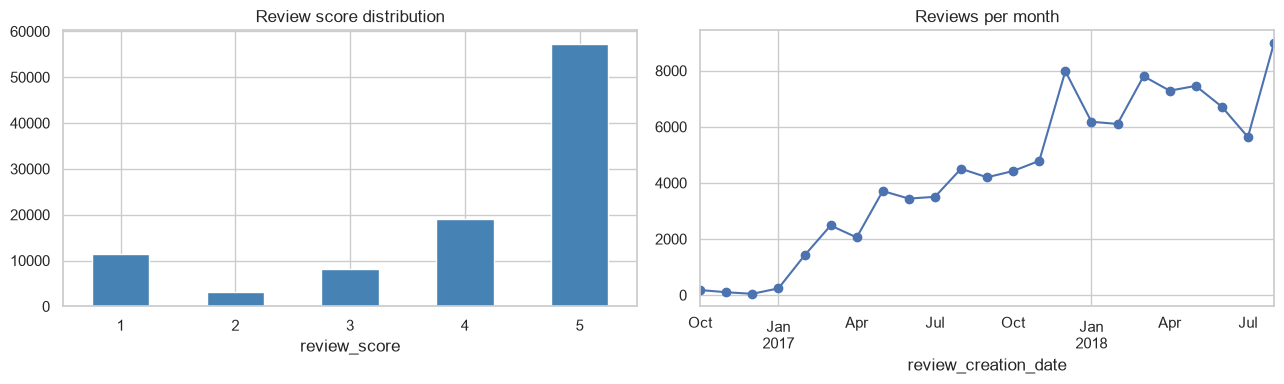

Mean score: 4.09 | with comment: 41%


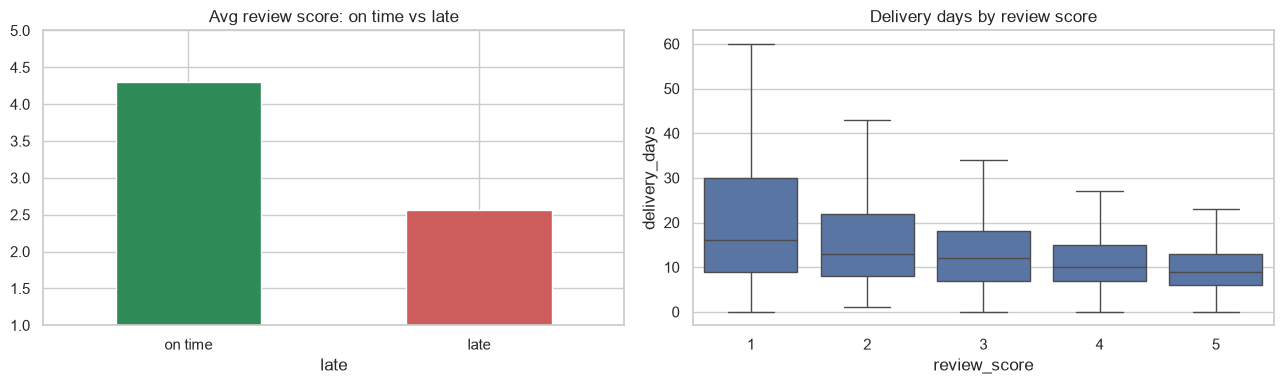

In [15]:
reviews["review_creation_date"] = pd.to_datetime(reviews.review_creation_date)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
reviews.review_score.value_counts().sort_index().plot.bar(ax=axes[0], rot=0, color="steelblue"); axes[0].set_title("Review score distribution")
reviews.review_creation_date.dt.to_period("M").value_counts().sort_index().plot(ax=axes[1], marker="o")
axes[1].set_title("Reviews per month")
plt.tight_layout(); plt.show()
print(f"Mean score: {reviews.review_score.mean():.2f} | with comment: {reviews.review_comment_message.notna().mean():.0%}")

# Delivery vs. score
r = reviews.drop_duplicates("order_id").merge(d[["order_id", "delivery_days", "late"]], on="order_id")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
r.groupby("late").review_score.mean().rename({False: "on time", True: "late"}).plot.bar(ax=axes[0], rot=0, color=["seagreen", "indianred"])
axes[0].set_title("Avg review score: on time vs late"); axes[0].set_ylim(1, 5)
sns.boxplot(data=r, x="review_score", y=r.delivery_days.clip(upper=60), ax=axes[1], showfliers=False)
axes[1].set_title("Delivery days by review score")
plt.tight_layout(); plt.show()

## 9. Products and categories

                               count     mean      std  min    25%    50%  \
product_name_lenght        32,341.00    48.48    10.25 5.00  42.00  51.00   
product_description_lenght 32,341.00   771.50   635.12 4.00 339.00 595.00   
product_photos_qty         32,341.00     2.19     1.74 1.00   1.00   1.00   
product_weight_g           32,949.00 2,276.47 4,282.04 0.00 300.00 700.00   
product_length_cm          32,949.00    30.82    16.91 7.00  18.00  25.00   
product_height_cm          32,949.00    16.94    13.64 2.00   8.00  13.00   
product_width_cm           32,949.00    23.20    12.08 6.00  15.00  20.00   

                                75%       max  
product_name_lenght           57.00     76.00  
product_description_lenght   972.00  3,992.00  
product_photos_qty             3.00     20.00  
product_weight_g           1,900.00 40,425.00  
product_length_cm             38.00    105.00  
product_height_cm             21.00    105.00  
product_width_cm              30.00    118.00  

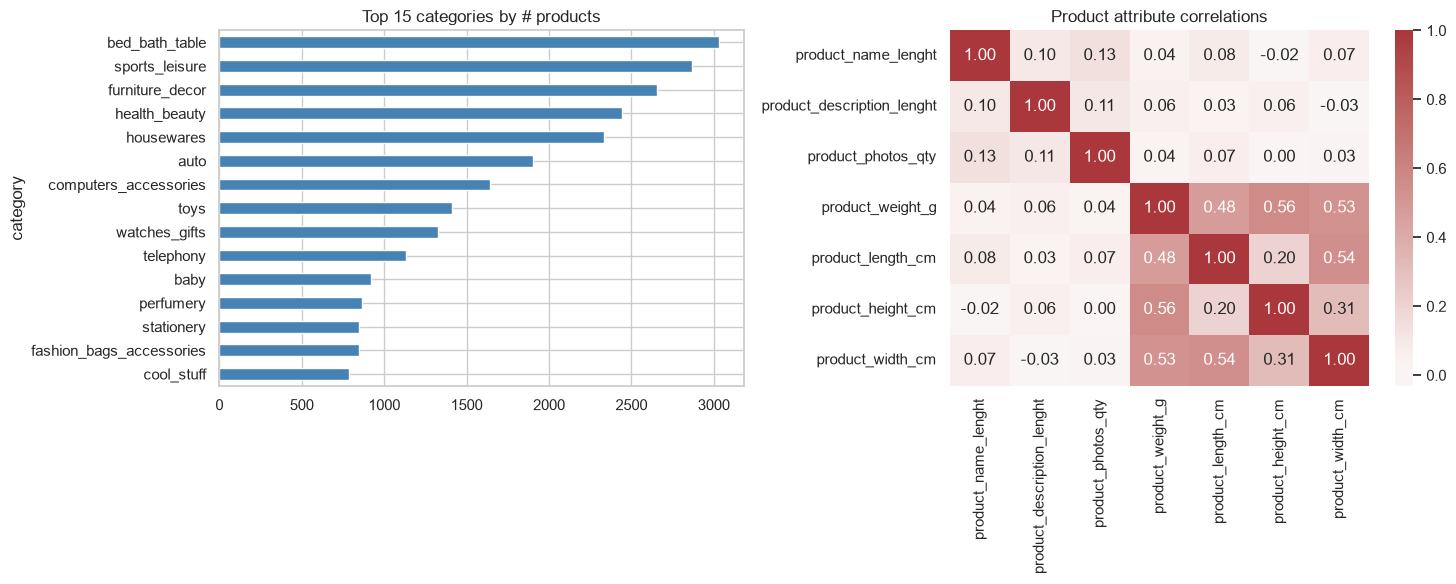

In [16]:
prod = products.merge(translation, on="product_category_name", how="left")
prod["category"] = prod.product_category_name_english.fillna(prod.product_category_name).fillna("unknown")
print(products.describe().T)
print("Categories:", prod.category.nunique(), "| untranslated categories:", prod[prod.product_category_name.notna() & prod.product_category_name_english.isna()].product_category_name.unique())

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
prod.category.value_counts().head(15).plot.barh(ax=axes[0], color="steelblue"); axes[0].invert_yaxis(); axes[0].set_title("Top 15 categories by # products")
sns.heatmap(products[["product_name_lenght", "product_description_lenght", "product_photos_qty", "product_weight_g",
                      "product_length_cm", "product_height_cm", "product_width_cm"]].corr(), annot=True, fmt=".2f", cmap="vlag", center=0, ax=axes[1])
axes[1].set_title("Product attribute correlations")
plt.tight_layout(); plt.show()

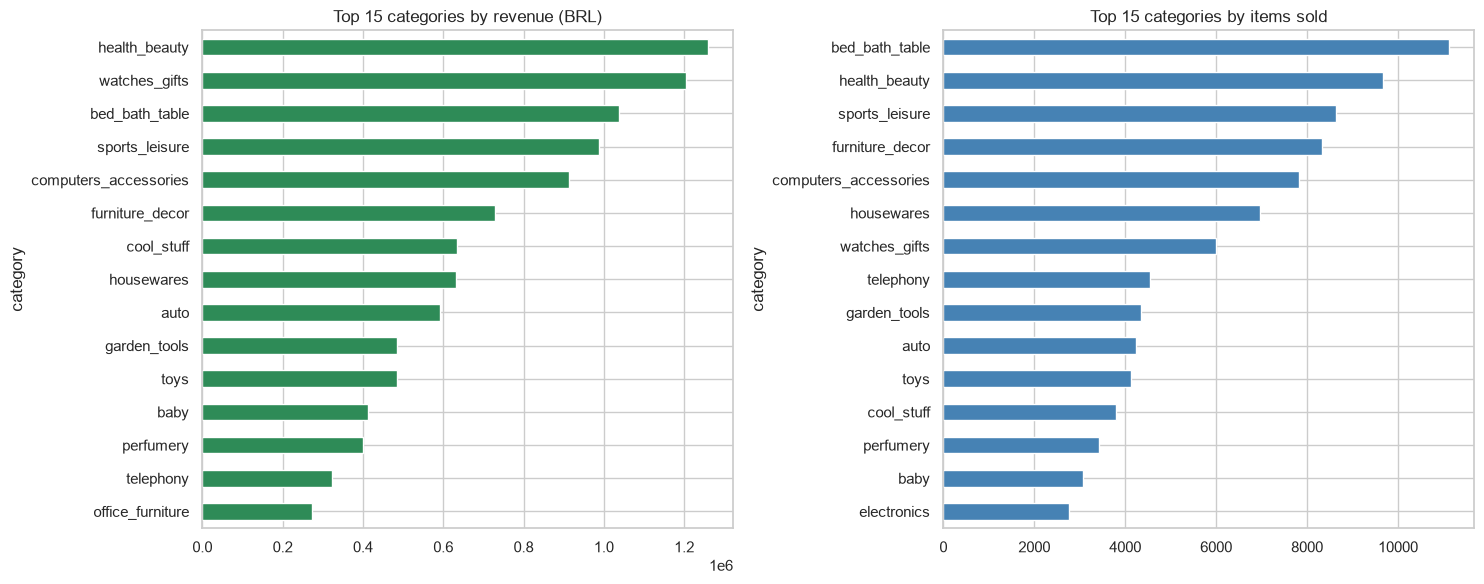

,items_sold,revenue,avg_price
category,,,
health_beauty,9670,"1,258,681.34",130.16
watches_gifts,5991,"1,205,005.68",201.14
bed_bath_table,11115,"1,036,988.68",93.30
sports_leisure,8641,"988,048.97",114.34
computers_accessories,7827,"911,954.32",116.51
furniture_decor,8334,"729,762.49",87.56
cool_stuff,3796,"635,290.85",167.36
housewares,6964,"632,248.66",90.79
auto,4235,"592,720.11",139.96


In [17]:
ip = items.merge(prod[["product_id", "category"]], on="product_id", how="left")
cat = ip.groupby("category").agg(items_sold=("order_id", "size"), revenue=("price", "sum"), avg_price=("price", "mean")).sort_values("revenue", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
cat.revenue.head(15).plot.barh(ax=axes[0], color="seagreen"); axes[0].invert_yaxis(); axes[0].set_title("Top 15 categories by revenue (BRL)")
cat.items_sold.sort_values(ascending=False).head(15).plot.barh(ax=axes[1], color="steelblue"); axes[1].invert_yaxis(); axes[1].set_title("Top 15 categories by items sold")
plt.tight_layout(); plt.show()
cat.head(10)

## 10. Customers, sellers and geography

Repeat customers: 3.1% of 96,096 unique customers
Top 10% of sellers generate 67% of revenue; 3095 active sellers


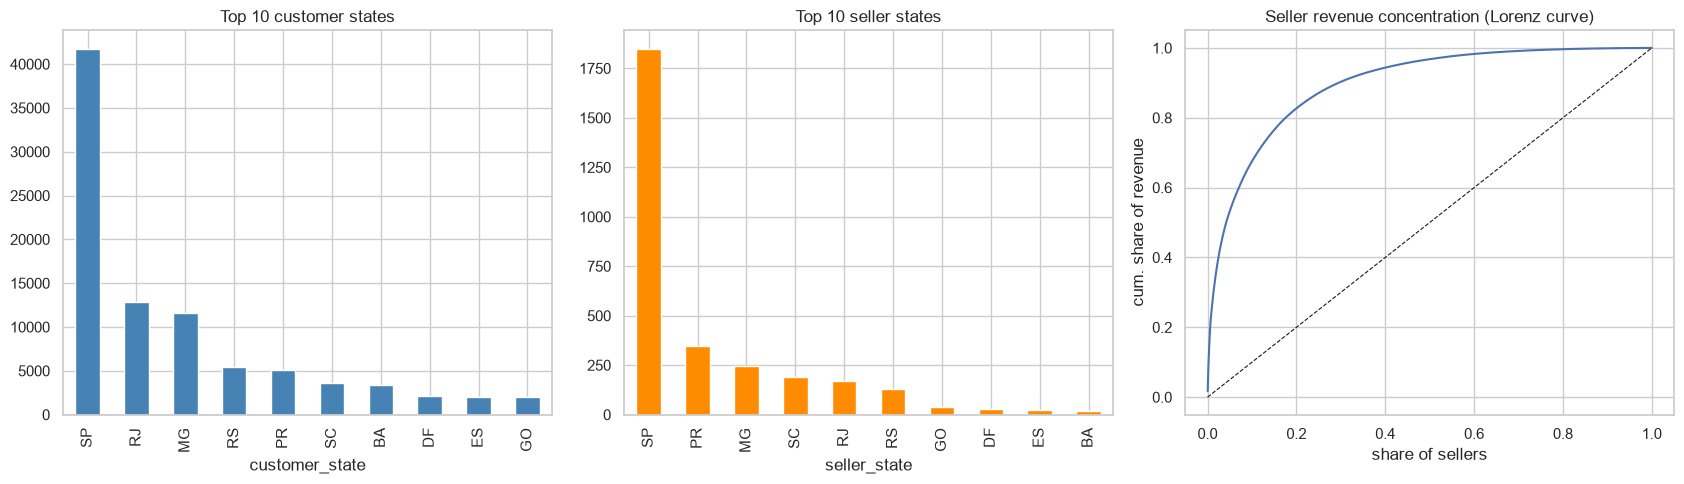

In [18]:
orders_per_cust = orders.merge(customers, on="customer_id").groupby("customer_unique_id").size()
print(f"Repeat customers: {(orders_per_cust > 1).mean():.1%} of {len(orders_per_cust):,} unique customers")

rev_seller = items.groupby("seller_id").price.sum().sort_values(ascending=False)
share = rev_seller.cumsum() / rev_seller.sum()
print(f"Top 10% of sellers generate {share.iloc[int(len(share) * .1) - 1]:.0%} of revenue; {len(rev_seller)} active sellers")

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
customers.customer_state.value_counts().head(10).plot.bar(ax=axes[0], color="steelblue"); axes[0].set_title("Top 10 customer states")
sellers.seller_state.value_counts().head(10).plot.bar(ax=axes[1], color="darkorange"); axes[1].set_title("Top 10 seller states")
axes[2].plot(np.arange(1, len(share) + 1) / len(share), share.values); axes[2].plot([0, 1], [0, 1], "k--", lw=.8)
axes[2].set_title("Seller revenue concentration (Lorenz curve)"); axes[2].set_xlabel("share of sellers"); axes[2].set_ylabel("cum. share of revenue")
plt.tight_layout(); plt.show()

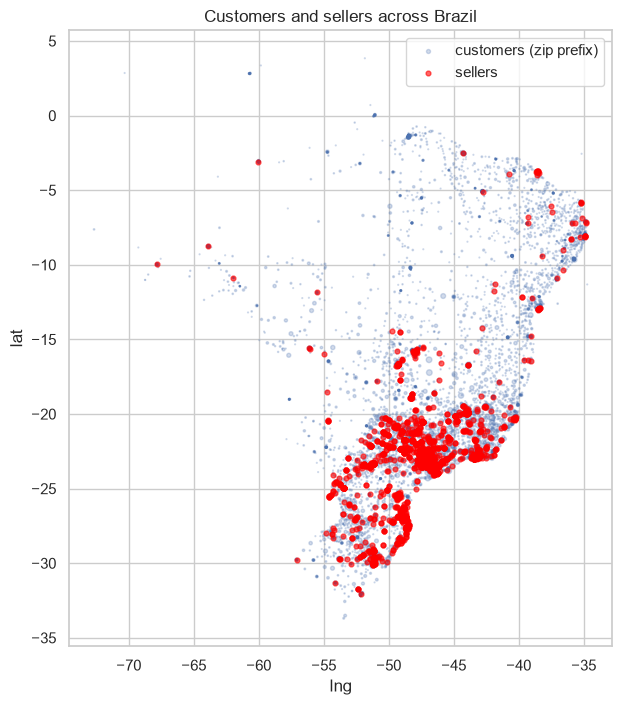

In [19]:
# Geolocation: zip prefixes repeat, so aggregate before plotting
geo = geolocation.groupby("geolocation_zip_code_prefix").agg(lat=("geolocation_lat", "mean"), lng=("geolocation_lng", "mean"))
geo = geo[geo.lat.between(-35, 6) & geo.lng.between(-75, -33)]  # keep points inside Brazil's bounding box
cust_geo = customers.merge(geo, left_on="customer_zip_code_prefix", right_index=True).groupby("customer_zip_code_prefix").agg(
    lat=("lat", "first"), lng=("lng", "first"), n=("customer_id", "size"))
sell_geo = sellers.merge(geo, left_on="seller_zip_code_prefix", right_index=True)
plt.figure(figsize=(7, 8))
plt.scatter(cust_geo.lng, cust_geo.lat, s=cust_geo.n.clip(upper=50) / 3, alpha=.25, label="customers (zip prefix)")
plt.scatter(sell_geo.lng, sell_geo.lat, s=12, c="red", alpha=.6, label="sellers")
plt.legend(); plt.title("Customers and sellers across Brazil"); plt.xlabel("lng"); plt.ylabel("lat"); plt.show()

## 11. Revenue over time and state-level view

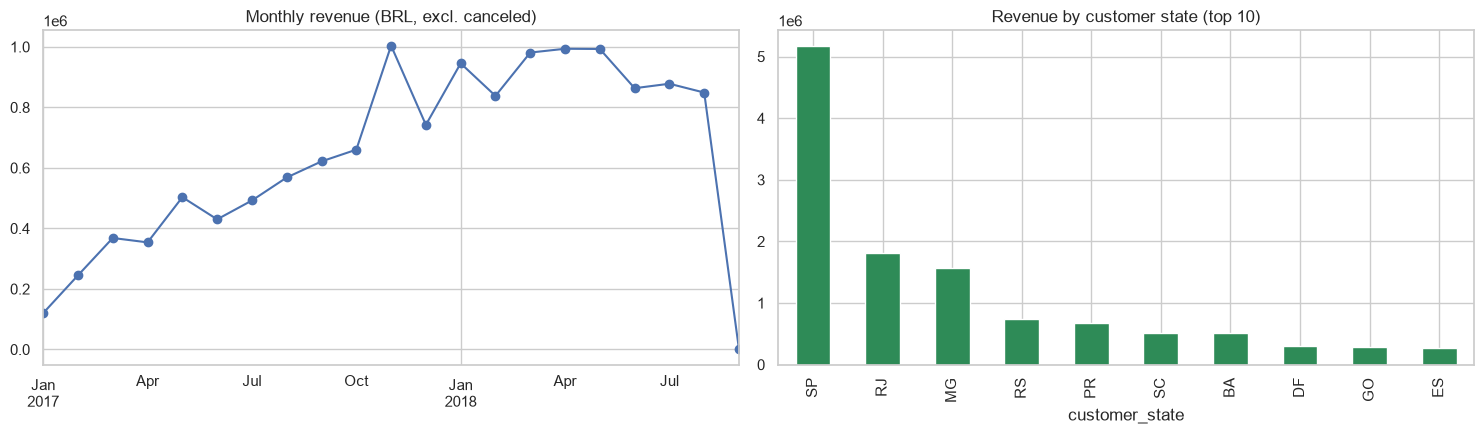

In [20]:
full = (items.merge(orders[["order_id", "order_purchase_timestamp", "order_status", "customer_id"]], on="order_id")
        .merge(customers[["customer_id", "customer_state"]], on="customer_id"))
full = full[full.order_status != "canceled"]
rev_m = full.set_index("order_purchase_timestamp").price.resample("MS").sum()
rev_m = rev_m[rev_m.index >= "2017-01-01"]   # 2016 is sparse
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
rev_m.plot(ax=axes[0], marker="o"); axes[0].set_title("Monthly revenue (BRL, excl. canceled)"); axes[0].set_xlabel("")
full.groupby("customer_state").price.sum().sort_values(ascending=False).head(10).plot.bar(ax=axes[1], color="seagreen")
axes[1].set_title("Revenue by customer state (top 10)")
plt.tight_layout(); plt.show()